In [1]:
import cupy as cp
import matplotlib.pyplot as plt

from tqdm.notebook import tqdm 

import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "text.usetex": False,
    "font.family": "serif",
    "axes.labelsize": 12,
    "font.size": 12,
    "legend.fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})


In [ ]:
q = 4
J_corsivo = 1
J = J_corsivo * 2**((q-1)/2) / cp.sqrt(q)
mu = 0.075
T = 0.01
beta = 1/T
M=500 # Max number of iterations for the solver

In [9]:
x = 0.5
S = 2**(int(cp.log2(100000))+1)

t_values = cp.linspace(0, beta, S, endpoint=False)
N_max = S // 4

n = cp.fft.fftfreq(S)*S
dealias_mask = cp.abs(n+0.5) < N_max

omega = 2*cp.pi/beta*(n + 0.5)
phase_shift = cp.exp(-1j*cp.pi/beta*t_values)
freq_shift = cp.exp(-1j * cp.pi * n / S) 

def trasf(G_t):
    return cp.fft.fft(G_t * phase_shift) * freq_shift * dealias_mask * beta/S

def antitrasf(G):
    return S/beta * cp.fft.ifft(G / freq_shift) * phase_shift.conj()

G_LL_t = cp.full(t_values.size, 0.5)
G_LL = 1.0/(1j*omega)
G_LL_free = G_LL

cost = 0.003
G_LR_t = cp.full(t_values.size, 1j*cost)
G_LR = 2 * cost / omega

diff = cp.empty((M), dtype=cp.float64)

for i in range(M):
    if i>= 2:

        check = diff[i-1]-diff[i-2]
        if check > 0:
            x = x/2.0

    Sigma_LL_t = J**2 *cp.power(G_LL_t, q-1)
    Sigma_LL = trasf(Sigma_LL_t)

    Sigma_LR_t = J**2 *cp.power(G_LR_t, q-1)
    Sigma_LR = trasf(Sigma_LR_t) 

    A = 1j * omega - Sigma_LL
    B = Sigma_LR - 1j*mu
    det = A**2 + B * B[::-1]

    G_LL_new = ((1-x)*G_LL + x * A/det) * dealias_mask
    Delta_G_LL = (G_LL_new - G_LL_free) * dealias_mask
    
    G_LR_new = ((1-x) * G_LR + x * B/det) * dealias_mask

    G_LL_new_t = 0.5 + cp.real(antitrasf(Delta_G_LL))
    G_LR_new_t = 1j*cp.imag(antitrasf(G_LR))

    residue_LL = cp.sum(cp.abs((G_LL - G_LL_new) * dealias_mask)**2)/beta
    residue_LR = cp.sum(cp.abs((G_LR - G_LR_new) * dealias_mask)**2)/beta

    diff[i] = (cp.sum(cp.abs(G_LL_new_t-G_LL_t)**2) + cp.sum(cp.abs(G_LR_new_t-G_LR_t)**2))*beta/S

    G_LL, G_LR = G_LL_new, G_LR_new

    G_LL_t, G_LR_t = G_LL_new_t, G_LR_new_t

    if (residue_LL < 1e-10) and (residue_LR < 1e-10):
        break    

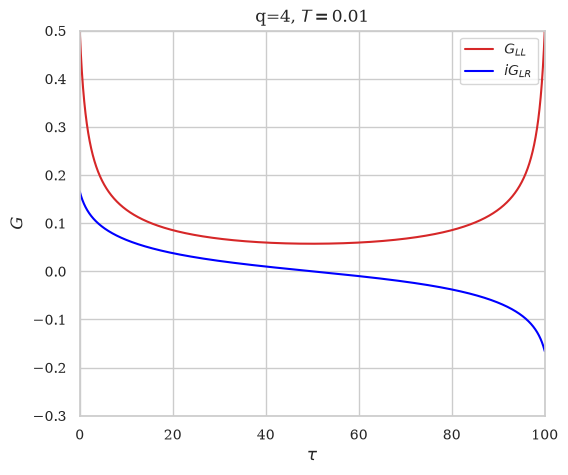

In [10]:
G_LL_t_CPU = G_LL_t.get()
G_LR_t_CPU = G_LR_t.imag.get()

plt.figure(figsize=(6, 5))

plt.plot(t_values.get(), G_LL_t_CPU, color="tab:red", label=r'$G_{LL}$')
plt.plot(t_values.get(), G_LR_t_CPU, color="blue", label=r'$iG_{LR}$')

plt.xlabel(fr'$\tau$')
plt.ylabel(fr'$G$')
plt.title(fr'q={q}, $T =${T}')


plt.xlim(0,beta)
plt.ylim(-0.3,0.5)
plt.legend()
plt.show()